# LAB 05 – BÀI TẬP THỰC HÀNH PHẦN 1: CÂY QUYẾT ĐỊNH VÀ RỪNG CÂY

## Thư viện và hàm dùng chung

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import glob, os
def find_file(patterns):
    """Tìm file CSV ở thư mục hiện tại hoặc trong /kaggle/input (khi chạy trên Kaggle)."""
    for p in patterns:
        hits = glob.glob(p) + glob.glob('/kaggle/input/**/' + p, recursive=True)
        if hits: return hits[0]
    raise FileNotFoundError('Không thấy file ' + str(patterns) + ' - hãy tải từ Kaggle và đặt cạnh notebook.')

Hàm run_tree_forest thực hiện toàn bộ phần mô hình cho một bộ dữ liệu đã tiền xử lý (X toàn số, y nhị phân), để hai bài dùng chung một quy trình:
1. Chia train/test 80:20 (có stratify để giữ tỷ lệ lớp).
2. Vẽ cây nông (max_depth=3) để đọc luật quyết định.
3. GridSearchCV cho cây (max_depth, min_samples_leaf), vẽ điểm train/validation theo độ sâu để phát hiện quá khớp.
4. GridSearchCV cho Random Forest (n_estimators, max_depth).
5. Đánh giá trên tập test (Accuracy, ROC AUC, báo cáo phân loại, confusion matrix) và vẽ feature importance.

In [2]:
def run_tree_forest(X, y, name):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(f'[{name}] train={X_train.shape}, test={X_test.shape}, tỷ lệ lớp 1 = {y.mean():.3f}')

    # 1) Cây nông để trực quan hóa
    dt_small = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
    plt.figure(figsize=(16, 7))
    plot_tree(dt_small, feature_names=list(X.columns), class_names=['0', '1'],
              filled=True, rounded=True, proportion=True, fontsize=8)
    plt.title(f'{name} - cây quyết định max_depth=3'); plt.show()

    # 2) GridSearchCV cho cây quyết định
    dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                           {'max_depth': [1, 2, 3, 4, 5, 6, 8, 10, 12], 'min_samples_leaf': [1, 5, 10, 20]},
                           scoring='roc_auc', cv=5, return_train_score=True)
    dt_grid.fit(X_train, y_train)
    print('Cây - tham số tốt nhất:', dt_grid.best_params_, '| ROC AUC CV = %.4f' % dt_grid.best_score_)
    res = pd.DataFrame(dt_grid.cv_results_)
    res = res[res['param_min_samples_leaf'] == dt_grid.best_params_['min_samples_leaf']]
    plt.figure(figsize=(6, 4))
    plt.plot(res['param_max_depth'].astype(int), res['mean_train_score'], '-o', label='train')
    plt.plot(res['param_max_depth'].astype(int), res['mean_test_score'], '-o', label='validation')
    plt.xlabel('max_depth'); plt.ylabel('ROC AUC'); plt.legend(); plt.title(f'{name} - quá khớp theo độ sâu'); plt.show()

    # 3) GridSearchCV cho Random Forest
    rf_grid = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                           {'n_estimators': [10, 50, 100, 200], 'max_depth': [3, 5, 8, 12]},
                           scoring='roc_auc', cv=5)
    rf_grid.fit(X_train, y_train)
    print('RF  - tham số tốt nhất:', rf_grid.best_params_, '| ROC AUC CV = %.4f' % rf_grid.best_score_)

    # 4) Đánh giá trên tập test
    rows = []
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
    for ax, (label, m) in zip(axs, [('Decision Tree', dt_grid.best_estimator_), ('Random Forest', rf_grid.best_estimator_)]):
        pred = m.predict(X_test)
        rows.append({'Model': label, 'Accuracy test': accuracy_score(y_test, pred),
                     'ROC AUC train': roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
                     'ROC AUC test': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
        ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=ax, colorbar=False, cmap='Blues')
        ax.set_title(label)
        print('\n=== ' + label + ' ===\n' + classification_report(y_test, pred))
    plt.tight_layout(); plt.show()

    # 5) Độ quan trọng của đặc trưng (Random Forest)
    imp = pd.Series(rf_grid.best_estimator_.feature_importances_, index=X.columns).sort_values()
    imp.plot.barh(figsize=(6, max(3, 0.3 * len(imp)))); plt.title(f'{name} - feature importance (RF)'); plt.show()
    return pd.DataFrame(rows).round(4), imp.sort_values(ascending=False)

# BÀI 1 – TITANIC
**Mục tiêu:** dự đoán hành khách có sống sót (Survived = 1) dựa trên hạng vé, giới tính, tuổi, số người thân đi cùng, giá vé, cảng lên tàu.
## 1.1 Nạp dữ liệu và khám phá

In [3]:
titanic = pd.read_csv(find_file(['train.csv', 'test.csv']))
print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Nhận xét:** Tập Titanic có 891 hành khách và 12 cột, trong đó Survived là nhãn cần dự đoán (1 = sống sót, 0 = tử vong). Các cột còn lại gồm thông tin nhân khẩu (Sex, Age), hạng vé (Pclass), người thân đi cùng (SibSp, Parch), giá vé (Fare), số cabin (Cabin) và cảng lên tàu (Embarked).

Age         177
Cabin       687
Embarked      2
dtype: int64

Tỷ lệ sống sót: 0.384


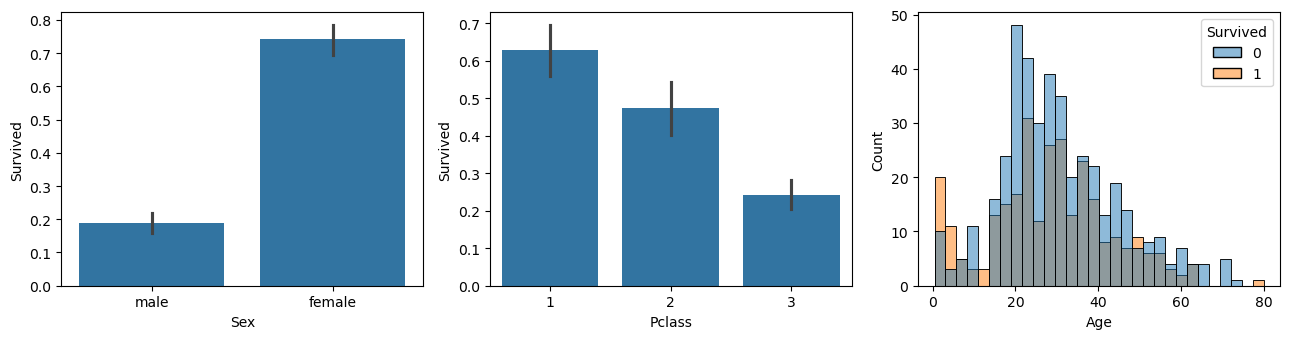

In [4]:
print(titanic.isna().sum()[lambda s: s > 0])         # cột bị thiếu
print('\nTỷ lệ sống sót:', titanic['Survived'].mean().round(3))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
sns.barplot(data=titanic, x='Sex', y='Survived', ax=axs[0])
sns.barplot(data=titanic, x='Pclass', y='Survived', ax=axs[1])
sns.histplot(data=titanic, x='Age', hue='Survived', bins=30, ax=axs[2])
plt.tight_layout(); plt.show()

**Nhận xét khám phá dữ liệu:**
- Dữ liệu thiếu ở 3 cột: Cabin thiếu 687/891 dòng (khoảng 77%), Age thiếu 177 dòng (khoảng 20%) và Embarked thiếu 2 dòng. Vì Cabin thiếu quá nhiều nên không điền giá trị mà chuyển thành biến nhị phân HasCabin (có hay không có số cabin).
- Tỷ lệ sống sót chung là 38,4%, tức dữ liệu hơi lệch về lớp tử vong (61,6%) nhưng chưa mất cân bằng nặng.
- Giới tính ảnh hưởng rất mạnh: nữ sống sót khoảng 74%, trong khi nam chỉ khoảng 19%.
- Hạng vé càng cao thì cơ hội sống càng lớn: hạng 1 khoảng 63%, hạng 2 khoảng 47%, hạng 3 khoảng 24%.
- Theo độ tuổi, nhóm trẻ em nhỏ có tỷ lệ sống sót cao hơn hẳn các nhóm còn lại, còn hành khách từ 20 đến 40 tuổi (nhóm đông nhất) có tỷ lệ tử vong cao.
- Ba quan sát này phù hợp với quy tắc phụ nữ và trẻ em được ưu tiên lên xuồng cứu sinh, nên Sex, Pclass và Age được kỳ vọng là các đặc trưng quan trọng.

## 1.2 Tiền xử lý
- Age thiếu → điền trung vị theo nhóm (Sex, Pclass); Embarked thiếu → điền mode.
- Cabin thiếu quá nhiều (~77%) → đổi thành biến nhị phân HasCabin.
- Tạo đặc trưng FamilySize = SibSp + Parch + 1, IsAlone.
- Bỏ các cột định danh/ít giá trị: PassengerId, Name, Ticket.
- Mã hóa Sex, Embarked bằng One-Hot (cây không cần chuẩn hóa dữ liệu số).

In [5]:
df = titanic.copy()
df['Age'] = df['Age'].fillna(df.groupby(['Sex', 'Pclass'])['Age'].transform('median')).fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['HasCabin'] = df['Cabin'].notna().astype(int)
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
df = df.drop(columns=[c for c in ['PassengerId', 'Name', 'Ticket', 'Cabin'] if c in df.columns])
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)
X1, y1 = df.drop(columns='Survived'), df['Survived']
print(X1.shape, '| còn thiếu:', int(X1.isna().sum().sum()))
X1.head()

(891, 11) | còn thiếu: 0


,Pclass,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,2,0,1,0,1
1,1,38.0,1,0,71.2833,1,2,0,0,0,0
2,3,26.0,0,0,7.9250,0,1,1,0,0,1
3,1,35.0,1,0,53.1000,1,2,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,1,1,0,1


**Nhận xét tiền xử lý:** Sau khi xử lý, dữ liệu còn 891 dòng và 11 đặc trưng, không còn giá trị thiếu. Age được điền bằng trung vị theo từng nhóm Sex và Pclass nên sát thực tế hơn so với dùng một trung vị chung cho toàn bộ. Hai biến mới FamilySize và IsAlone gom thông tin SibSp và Parch thành đại lượng dễ diễn giải hơn (đi một mình hay đi cùng gia đình). Sex và Embarked được mã hóa one-hot thành Sex_male, Embarked_Q, Embarked_S. Vì dùng mô hình dựa trên cây nên không cần chuẩn hóa các biến số như Fare hay Age.

## 1.3 Cây quyết định, Random Forest và đánh giá

[Titanic] train=(712, 11), test=(179, 11), tỷ lệ lớp 1 = 0.384


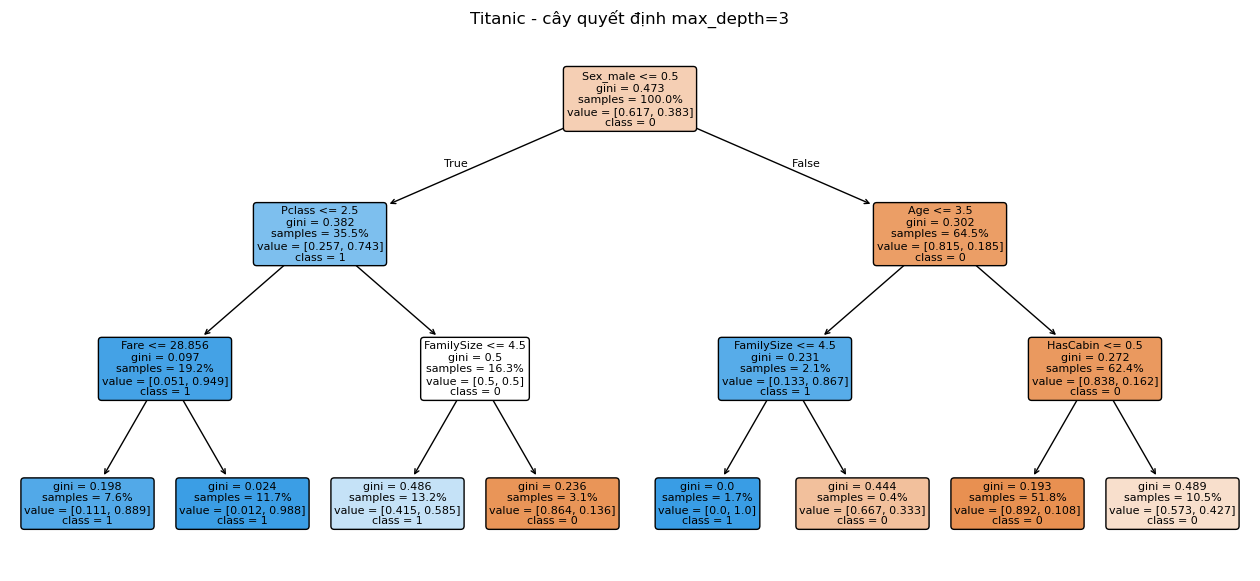

Cây - tham số tốt nhất: {'max_depth': 3, 'min_samples_leaf': 5} | ROC AUC CV = 0.8594


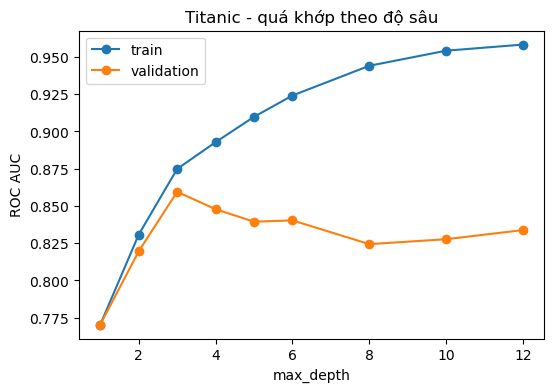

RF  - tham số tốt nhất: {'max_depth': 5, 'n_estimators': 50} | ROC AUC CV = 0.8744

=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.80      0.87      0.83       110
           1       0.76      0.65      0.70        69

    accuracy                           0.79       179
   macro avg       0.78      0.76      0.77       179
weighted avg       0.79      0.79      0.78       179


=== Random Forest ===
              precision    recall  f1-score   support

           0       0.77      0.86      0.82       110
           1       0.73      0.59      0.66        69

    accuracy                           0.76       179
   macro avg       0.75      0.73      0.74       179
weighted avg       0.76      0.76      0.75       179



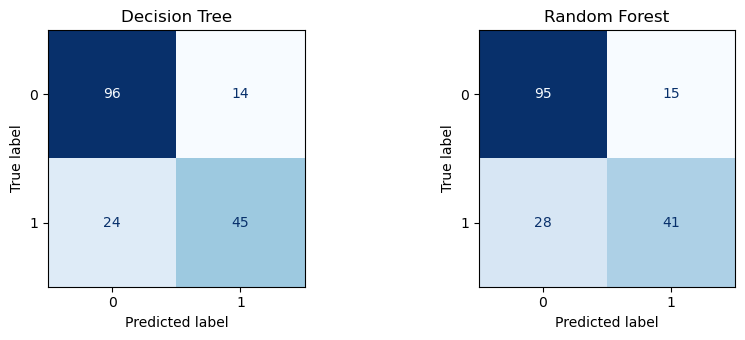

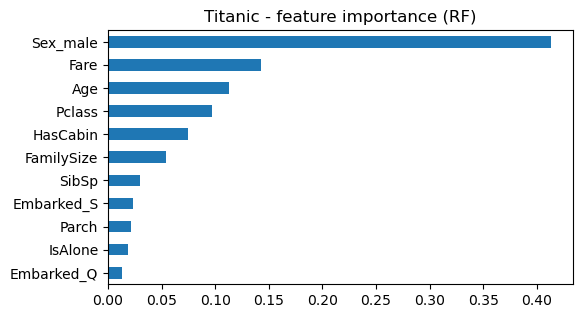

,Model,Accuracy test,ROC AUC train,ROC AUC test
0,Decision Tree,0.7877,0.872,0.8043
1,Random Forest,0.7598,0.920,0.8373


In [6]:
res1, imp1 = run_tree_forest(X1, y1, 'Titanic')
res1

### Nhận xét kết quả bài 1 – Titanic

**1. Cây quyết định độ sâu 3 (đọc luật):**
- Nút gốc tách theo Sex_male, nghĩa là giới tính là yếu tố phân tách tốt nhất. Nhóm nữ chiếm 35,5% dữ liệu với tỷ lệ sống 74,3%; nhóm nam chiếm 64,5% với tỷ lệ sống chỉ 18,5%.
- Với nữ, nút tiếp theo tách theo Pclass: nữ hạng 1 và 2 sống khoảng 95%. Nữ hạng 3 chỉ sống khoảng 50%: nếu đi cùng gia đình từ 4 người trở xuống thì tỷ lệ sống là 58,5%, còn nếu gia đình đông (FamilySize lớn hơn 4,5) thì hầu hết tử vong (chỉ 13,6% sống).
- Với nam, nút tiếp theo tách theo Age: bé trai từ 3,5 tuổi trở xuống có 86,7% sống, còn nam trưởng thành chỉ sống 16,2%; nam trưởng thành không có cabin (chiếm 51,8% toàn bộ dữ liệu) chỉ sống khoảng 10,8%.
- Cây tìm ra đúng quy luật phụ nữ và trẻ em được ưu tiên, cộng với lợi thế của hành khách hạng cao.

**2. Quá khớp theo độ sâu:** Điểm ROC AUC trên tập train tăng đều từ khoảng 0,77 lên khoảng 0,96 khi tăng max_depth, nhưng điểm validation đạt đỉnh ở max_depth = 3 (khoảng 0,86) rồi giảm và dao động quanh 0,83 đến 0,84. Khoảng cách giữa hai đường mở rộng dần từ độ sâu 4 trở đi, tức cây càng sâu càng ghi nhớ dữ liệu train (phương sai cao). Vì vậy GridSearchCV chọn max_depth = 3 và min_samples_leaf = 5, với ROC AUC kiểm định chéo 0,8594.

**3. Random Forest:** Tham số tốt nhất là max_depth = 5 và n_estimators = 50, ROC AUC kiểm định chéo 0,8744, cao hơn cây đơn khoảng 0,015.

**4. So sánh trên tập test (179 hành khách):**

| Mô hình | Accuracy test | ROC AUC train | ROC AUC test | Recall lớp 1 | Số sót người sống sót (FN) | Số báo nhầm (FP) |
|---|---|---|---|---|---|---|
| Decision Tree | 0,7877 | 0,872 | 0,8043 | 0,65 | 24 | 14 |
| Random Forest | 0,7598 | 0,920 | 0,8373 | 0,59 | 28 | 15 |

- Random Forest xếp hạng tốt hơn (ROC AUC test cao hơn khoảng 0,033), nhưng accuracy tại ngưỡng 0,5 lại thấp hơn cây đơn 5 mẫu (136 so với 141 mẫu đúng). Hai chỉ số này không mâu thuẫn: ROC AUC đo khả năng sắp xếp đúng thứ tự giữa hai lớp trên mọi ngưỡng, còn accuracy chỉ đo ở một ngưỡng cố định.
- Cả hai mô hình đều bỏ sót khá nhiều người sống sót (recall lớp 1 chỉ 0,59 đến 0,65) vì lớp sống sót là lớp thiểu số. Có thể cải thiện bằng class_weight=balanced hoặc hạ ngưỡng quyết định.
- Khoảng cách ROC AUC train và test của Random Forest (0,920 so với 0,837) lớn hơn của cây (0,872 so với 0,804), nghĩa là Random Forest vẫn còn quá khớp ở mức vừa phải, và tập test chỉ có 179 mẫu nên chênh lệch vài mẫu chưa đủ kết luận mô hình nào tốt hơn một cách chắc chắn.

**5. Độ quan trọng của đặc trưng (Random Forest):** Sex_male vượt trội (khoảng 0,41), tiếp theo là Fare (khoảng 0,14), Age (khoảng 0,11), Pclass (khoảng 0,10), HasCabin (khoảng 0,07) và FamilySize (khoảng 0,05). Các biến Embarked_Q, Embarked_S, IsAlone, Parch và SibSp có đóng góp rất nhỏ. Kết quả này khớp với cây quyết định và phần khám phá dữ liệu. Lưu ý Fare và Pclass tương quan với nhau nên mức quan trọng của hai biến này bị chia sẻ cho nhau.

**Kết luận bài 1:** Với dữ liệu nhỏ (891 mẫu) và nhiều nhiễu, một cây nông (độ sâu 3) đã bắt được phần lớn quy luật và dễ diễn giải; Random Forest cho khả năng xếp hạng tốt hơn nhưng không làm tăng accuracy rõ rệt. Giới tính, hạng vé, giá vé và tuổi là các yếu tố quyết định cơ hội sống sót.

# BÀI 2 – DỰ ĐOÁN BỆNH TIỂU ĐƯỜNG
**Mục tiêu:** dự đoán nhãn diabetes (1 = mắc tiểu đường) từ các thuộc tính nhân khẩu học, tiền sử hút thuốc và chỉ số sức khỏe trong diabetes_prediction_dataset.csv.
## 2.1 Nạp dữ liệu và khám phá

In [10]:
diab = pd.read_csv(find_file(['diabetes_prediction_dataset.csv']))
print(diab.shape)
display_cols = diab.describe(include='all').T
print(display_cols)
print('\nTỷ lệ diabetes=1:', diab['diabetes'].mean().round(3))
print('\nPhân bố nhãn:')
print(diab['diabetes'].value_counts())

(100000, 9)
                        count unique      top   freq       mean        std  \
gender                 100000      3   Female  58552        NaN        NaN   
age                  100000.0    NaN      NaN    NaN  41.885856   22.51684   
hypertension         100000.0    NaN      NaN    NaN    0.07485    0.26315   
heart_disease        100000.0    NaN      NaN    NaN    0.03942   0.194593   
smoking_history        100000      6  No Info  35816        NaN        NaN   
bmi                  100000.0    NaN      NaN    NaN  27.320767   6.636783   
HbA1c_level          100000.0    NaN      NaN    NaN   5.527507   1.070672   
blood_glucose_level  100000.0    NaN      NaN    NaN  138.05806  40.708136   
diabetes             100000.0    NaN      NaN    NaN      0.085   0.278883   

                       min    25%    50%    75%    max  
gender                 NaN    NaN    NaN    NaN    NaN  
age                   0.08   24.0   43.0   60.0   80.0  
hypertension           0.0    0.0   

**Nhận xét dữ liệu:** Bộ dữ liệu diabetes_prediction_dataset có 100.000 bản ghi và 9 cột, không có giá trị thiếu. Có 2 thuộc tính phân loại là gender (3 giá trị) và smoking_history (6 giá trị, trong đó No Info chiếm 35,8%), các thuộc tính còn lại là số. Nhãn diabetes **mất cân bằng nặng**: chỉ 8.500 mẫu mắc bệnh (8,5%) so với 91.500 mẫu không mắc (91,5%). Một mô hình luôn dự đoán không mắc bệnh đã đạt accuracy 91,5% nhưng hoàn toàn vô dụng, nên khi đánh giá phải xem thêm recall, precision và ROC AUC của lớp mắc bệnh thay vì chỉ nhìn accuracy. Ngoài ra bmi có giá trị lớn nhất 95,69 và blood_glucose_level lớn nhất 300, cho thấy có các ca ngoại lệ nhưng mô hình cây không nhạy với giá trị ngoại lệ nên không cần loại bỏ.

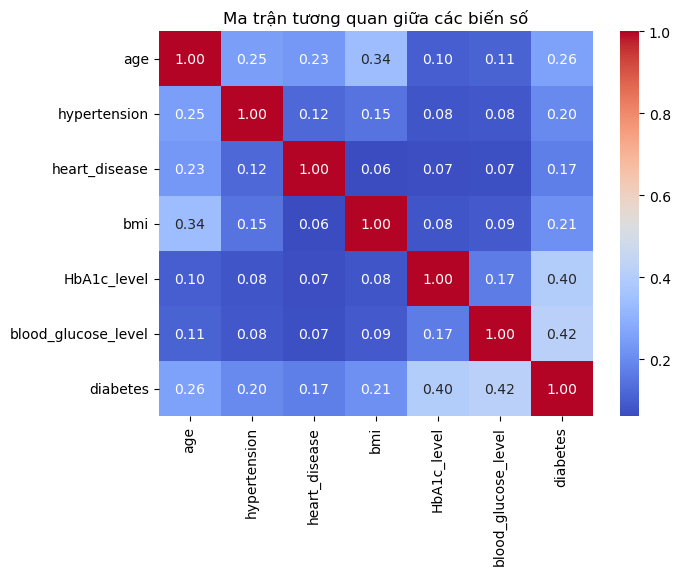

In [11]:
plt.figure(figsize=(7, 5))
numeric_corr = diab.select_dtypes(include='number').corr()
sns.heatmap(numeric_corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Ma trận tương quan giữa các biến số'); plt.show()

**Nhận xét tương quan:** Hai biến tương quan mạnh nhất với nhãn diabetes là blood_glucose_level (0,42) và HbA1c_level (0,40), tiếp theo là age (0,26), bmi (0,21), hypertension (0,20) và heart_disease (0,17). Các biến độc lập với nhau tương quan yếu (cao nhất là age và bmi: 0,34), nên không có hiện tượng đa cộng tuyến đáng kể. Cần nhớ hệ số Pearson chỉ đo quan hệ tuyến tính, còn cây quyết định và Random Forest có thể khai thác cả quan hệ phi tuyến theo ngưỡng.

## 2.2 Tiền xử lý
Bộ dữ liệu có hai thuộc tính dạng phân loại (gender, smoking_history) và không có giá trị thiếu. Mã hóa các thuộc tính này bằng one-hot encoding; tách cột diabetes làm nhãn cần dự đoán.

In [12]:
d2 = diab.copy()
y2 = d2.pop('diabetes')
X2 = pd.get_dummies(d2, columns=['gender', 'smoking_history'], dtype=int)
print('Kích thước X2:', X2.shape)
print('Số giá trị thiếu trong X2:', int(X2.isna().sum().sum()))
print('Các lớp của y2:', sorted(y2.unique()))

Kích thước X2: (100000, 15)
Số giá trị thiếu trong X2: 0
Các lớp của y2: [np.int64(0), np.int64(1)]


**Nhận xét tiền xử lý:** Sau khi mã hóa one-hot gender và smoking_history, ma trận đặc trưng có 15 cột (6 biến số gốc và 9 cột one-hot), không còn giá trị thiếu. Nhãn y2 gồm hai lớp 0 và 1. Không cần chuẩn hóa dữ liệu vì cây và rừng cây không phụ thuộc thang đo.

## 2.3 Cây quyết định, Random Forest và đánh giá

[Diabetes] train=(80000, 15), test=(20000, 15), tỷ lệ lớp 1 = 0.085


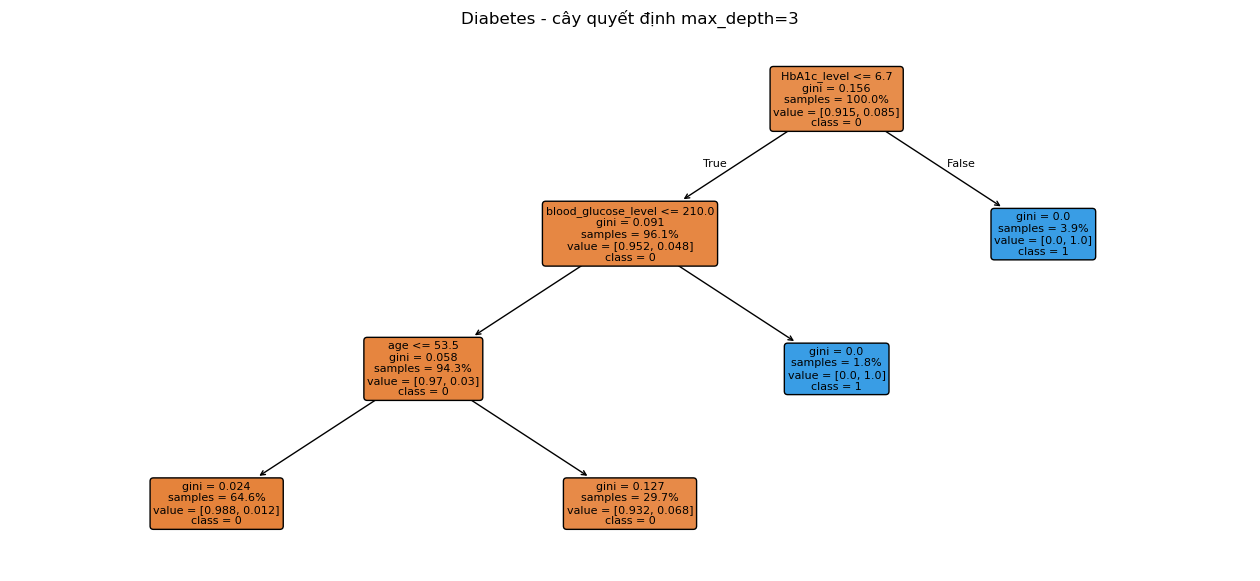

Cây - tham số tốt nhất: {'max_depth': 10, 'min_samples_leaf': 10} | ROC AUC CV = 0.9738


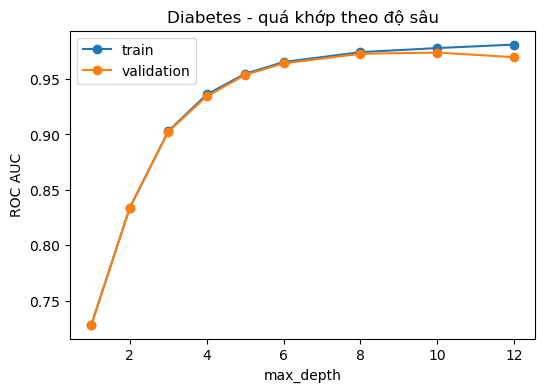

RF  - tham số tốt nhất: {'max_depth': 12, 'n_estimators': 200} | ROC AUC CV = 0.9724

=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     18300
           1       0.97      0.69      0.80      1700

    accuracy                           0.97     20000
   macro avg       0.97      0.84      0.89     20000
weighted avg       0.97      0.97      0.97     20000


=== Random Forest ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.99     18300
           1       1.00      0.68      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.98      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000



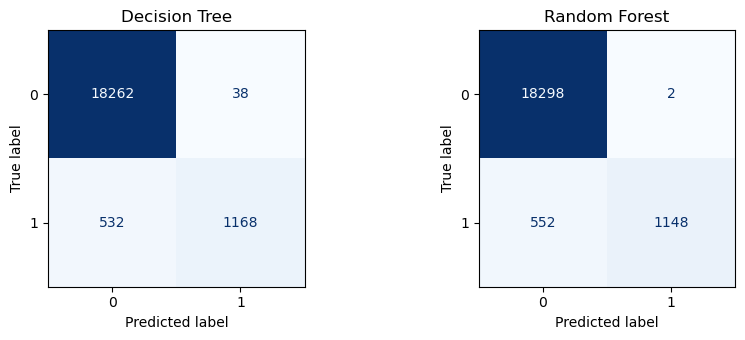

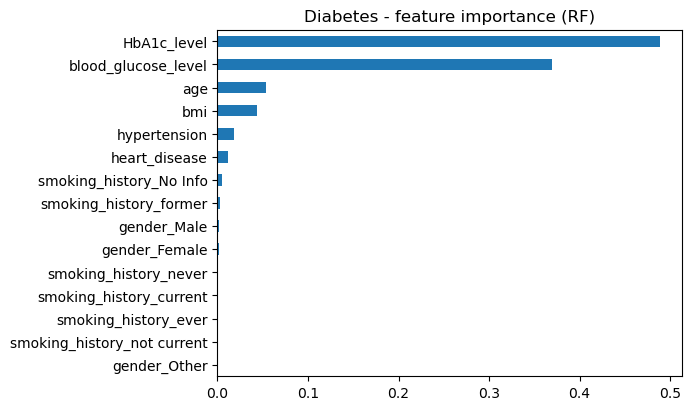

,Model,Accuracy test,ROC AUC train,ROC AUC test
0,Decision Tree,0.9715,0.9774,0.9746
1,Random Forest,0.9723,0.9824,0.9726


In [13]:
res2, imp2 = run_tree_forest(X2, y2, 'Diabetes')
res2

### Nhận xét kết quả bài 2 – Bệnh tiểu đường

**1. Cây quyết định độ sâu 3:**
- Nút gốc tách theo HbA1c_level lớn hơn 6,7: toàn bộ 3,9% mẫu có HbA1c cao hơn ngưỡng này đều mắc tiểu đường (nút thuần, gini = 0). Điều này khớp với kiến thức y khoa, vì HbA1c từ 6,5% trở lên là một tiêu chuẩn chẩn đoán đái tháo đường.
- Với nhóm còn lại, cây tiếp tục tách theo blood_glucose_level lớn hơn 210: 1,8% mẫu này cũng 100% mắc bệnh. Phần dư được tách theo age (53,5 tuổi): nhóm trên 53,5 tuổi có tỷ lệ mắc bệnh 6,8%, cao hơn nhiều so với nhóm trẻ (1,2%).
- Như vậy bài toán chủ yếu được quyết định bởi hai chỉ số xét nghiệm là HbA1c và đường huyết, tuổi đóng vai trò phụ.

**2. Quá khớp theo độ sâu:** Hai đường train và validation gần như trùng khít từ độ sâu 1 đến 6 và chỉ tách rất nhẹ ở các độ sâu lớn. Điểm validation cao nhất ở max_depth = 10 (ROC AUC kiểm định chéo 0,9738, min_samples_leaf = 10) rồi giảm nhẹ ở độ sâu 12. Do tập train lớn (80.000 mẫu) nên cây ít bị quá khớp hơn nhiều so với bài Titanic.

**3. Random Forest:** Tham số tốt nhất là max_depth = 12 và n_estimators = 200 với ROC AUC kiểm định chéo 0,9724, gần bằng cây đơn (0,9738). Cả hai giá trị tốt nhất đều nằm ở biên lớn nhất của lưới, nên có thể mở rộng lưới (ví dụ max_depth lớn hơn) để kiểm tra xem còn cải thiện được không.

**4. So sánh trên tập test (20.000 mẫu, trong đó 1.700 ca mắc bệnh):**

| Mô hình | Accuracy | ROC AUC train | ROC AUC test | Precision lớp 1 | Recall lớp 1 | Bỏ sót ca bệnh (FN) | Báo nhầm (FP) |
|---|---|---|---|---|---|---|---|
| Decision Tree | 0,9715 | 0,9774 | 0,9746 | 0,97 | 0,69 | 532 | 38 |
| Random Forest | 0,9723 | 0,9824 | 0,9726 | 1,00 | 0,68 | 552 | 2 |

- Hai mô hình gần như tương đương: accuracy khoảng 97,2% và ROC AUC test khoảng 0,973. Random Forest không cải thiện so với một cây đơn đã được điều chỉnh tham số tốt, vì cấu trúc dữ liệu đơn giản (chủ yếu dựa vào HbA1c và đường huyết) nên một cây vừa đủ sâu đã nắm bắt gần hết thông tin.
- Accuracy 97% nghe có vẻ rất cao, nhưng so với mức nền 91,5% (luôn đoán không bệnh) thì mức tăng thực chất không lớn. Điểm yếu thật sự là recall của lớp mắc bệnh chỉ khoảng 0,68 đến 0,69: cả hai mô hình bỏ sót hơn 500 trên 1.700 ca bệnh (khoảng 31 đến 32%).
- Random Forest có precision gần như tuyệt đối (chỉ báo nhầm 2 ca) nhưng đổi lại bỏ sót nhiều hơn; mô hình rất thận trọng khi kết luận có bệnh. Với bài toán y tế, bỏ sót người bệnh thường nghiêm trọng hơn báo nhầm, nên nên ưu tiên recall: dùng class_weight=balanced, hạ ngưỡng xác suất dưới 0,5, hoặc chọn mô hình theo F1 hay recall thay vì ROC AUC.
- Khoảng cách ROC AUC train và test rất nhỏ (cây: 0,0028; rừng: 0,0098) nên hầu như không có quá khớp.

**5. Độ quan trọng của đặc trưng (Random Forest):** HbA1c_level (khoảng 0,49) và blood_glucose_level (khoảng 0,37) chiếm tổng cộng khoảng 86% tầm quan trọng. Tiếp theo là age (khoảng 0,05), bmi (khoảng 0,04), hypertension và heart_disease (khoảng 0,01 đến 0,02). Các cột one-hot của gender và smoking_history gần như bằng 0, nghĩa là có thể loại bỏ chúng mà hầu như không ảnh hưởng đến kết quả.

**Kết luận bài 2:** Chỉ cần HbA1c và đường huyết đã dự đoán được phần lớn ca bệnh. Với dữ liệu lớn và đơn giản như vậy, cây quyết định có điều chỉnh độ sâu đã đủ tốt và có lợi thế dễ giải thích; Random Forest không mang lại lợi ích rõ rệt. Thách thức chính là dữ liệu mất cân bằng nên cần tối ưu recall của lớp mắc bệnh.

---
### Nhận xét tổng hợp

| Tiêu chí | Titanic | Bệnh tiểu đường |
|---|---|---|
| Kích thước dữ liệu | 891 mẫu | 100.000 mẫu |
| Cân bằng lớp | Khá cân bằng (38,4% lớp 1) | Mất cân bằng (8,5% lớp 1) |
| Độ sâu cây tốt nhất | 3 | 10 |
| Quá khớp | Rõ rệt khi cây sâu | Gần như không đáng kể |
| Random Forest so với cây đơn | ROC AUC test cao hơn, accuracy thấp hơn | Gần như bằng nhau |
| Đặc trưng quan trọng nhất | Sex_male, Fare, Age, Pclass | HbA1c_level, blood_glucose_level |

Rút ra:
- (1) Dữ liệu càng nhỏ và nhiễu thì cây càng dễ quá khớp, nên cần giới hạn độ sâu bằng kiểm định chéo.
- (2) Random Forest không phải lúc nào cũng vượt trội so với một cây đơn đã được điều chỉnh tốt; lợi ích phụ thuộc vào độ phức tạp của dữ liệu.
- (3) Cần chọn thước đo phù hợp với bài toán: accuracy dễ gây hiểu lầm khi lớp mất cân bằng, nên phải xem thêm recall, precision và ROC AUC.